# 13. Modelo LSTM final — predicción semanal de brotes de dengue

## 1. Definición del problema
Queremos anticipar **brote/no brote en la semana t+4** para los municipios elegibles de
Tolima, Meta y Valle del Cauca, con información disponible hasta la semana t.
Una observación es una secuencia de doce semanas de un solo municipio.

Este libro presenta un pipeline completo con **una única configuración**. El notebook 12
contiene los experimentos que permitieron seleccionarla. Aquí no es necesario ejecutarlo.

**Modelo elegido:** LSTM de 32 unidades y Dense de 16 unidades. Ganó por F2 medio en la
validación temporal; entre los cuatro finalistas también tuvo menos FN en la validación
final (197). Esto no significa que sea el modelo con menos FN en test.

Usamos **F2 = 5·TP / (5·TP + 4·FN + FP)**: perder un brote recibe mayor importancia,
pero las falsas alarmas también tienen coste. Minimizar únicamente FN favorecería
la regla trivial de anunciar brote siempre.

**Cómo ejecutar:** seleccionar un kernel de Python 3.11–3.13 y usar *Restart Kernel and Run All*.
Por defecto se reutiliza el modelo guardado. Cada etapa explica su entrada, transformación y salida.

## 2. Variables y configuración
Centralizamos las decisiones para que puedan revisarse antes de ejecutar el pipeline.
`REENTRENAR=False` carga artefactos compatibles; `True` entrena una sola configuración.
Las rutas se resuelven tanto desde la raíz del proyecto como desde `notebooks/`.

In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
import shutil
import subprocess
import importlib.util

RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/download_datasets.py').exists()), None)
if RAIZ is None:
    raise RuntimeError('Ejecuta desde la raíz del proyecto o desde notebooks/.')
RAW = RAIZ / 'data/raw'
SALIDA = RAIZ / 'models/lstm/final'
ORIGEN = (RAIZ / 'models/lstm/experimentos_optuna/3553611f96745176'
          / 'finalistas/w12_7f26a5e6e4')
REENTRENAR = False
INSTALAR_FALTANTES = True
CONFIG = {
    'version_pipeline': 'lstm-final-v1',
    'departamentos': [50, 73, 76], 'anio_inicio': 2007,
    'anio_fin_train': 2021, 'anios_validation': [2022, 2023], 'anios_test': [2024, 2025],
    'referencia_inicio': 2007, 'referencia_fin': 2019,
    'excluir_referencia': [2010, 2013, 2016, 2019],
    'min_anios_con_casos': 10, 'min_casos_train': 200, 'min_anios_referencia': 3,
    'ventanas_medias': [3, 6, 9], 'ventana': 12, 'historia_minima': 26,
    'horizonte': 4, 'purga_semanas': 4, 'epochs': 30, 'paciencia': 5, 'semilla': 42,
}
PARAMETROS = {'n_capas': 1, 'unidades_1': 32, 'dropout': 0.0, 'dense': 16,
              'learning_rate': 0.0012821922953669118, 'batch_size': 256}
FEATURES = ['casos', 'temperatura', 'lluvia', 'semana_sin', 'semana_cos',
            'temperatura_faltante', 'lluvia_faltante',
            'p75_historico', 'p75_media_3', 'p75_media_6', 'p75_media_9']
# Limitamos hilos para permitir la ejecución reproducible en CPU.
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_NUM_INTRAOP_THREADS', '2')
os.environ.setdefault('TF_NUM_INTEROP_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('MPLCONFIGDIR', str(SALIDA / 'matplotlib_cache'))
print('Destino de los artefactos:', SALIDA)
print(json.dumps(CONFIG, indent=2, ensure_ascii=False))

Destino de los artefactos: /home/sergioba/code/university/microproyecto-tema3/models/lstm/final
{
  "version_pipeline": "lstm-final-v1",
  "departamentos": [
    50,
    73,
    76
  ],
  "anio_inicio": 2007,
  "anio_fin_train": 2021,
  "anios_validation": [
    2022,
    2023
  ],
  "anios_test": [
    2024,
    2025
  ],
  "referencia_inicio": 2007,
  "referencia_fin": 2019,
  "excluir_referencia": [
    2010,
    2013,
    2016,
    2019
  ],
  "min_anios_con_casos": 10,
  "min_casos_train": 200,
  "min_anios_referencia": 3,
  "ventanas_medias": [
    3,
    6,
    9
  ],
  "ventana": 12,
  "historia_minima": 26,
  "horizonte": 4,
  "purga_semanas": 4,
  "epochs": 30,
  "paciencia": 5,
  "semilla": 42
}


## 3. Dependencias y descarga de datos
Usamos pandas para las tablas, scikit-learn para preprocesamiento y métricas, y TensorFlow/Keras
para la red. Las dependencias específicas están en `requirements-lstm-final.txt`.
Si faltan los CSV locales, se invoca el descargador del proyecto; puede necesitar acceso a Kaggle.

In [2]:
MODULOS = ['numpy', 'pandas', 'pyarrow', 'sklearn', 'matplotlib', 'tensorflow',
           'epiweeks', 'joblib', 'kagglehub', 'dotenv']
faltan = [m for m in MODULOS if importlib.util.find_spec(m) is None]
if faltan:
    if not INSTALAR_FALTANTES:
        raise ImportError(f'Instala notebooks/requirements-lstm-final.txt. Faltan: {faltan}')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r',
                           str(RAIZ / 'notebooks/requirements-lstm-final.txt')])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn
import joblib
from epiweeks import Week
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (confusion_matrix, average_precision_score, roc_auc_score,
                             ConfusionMatrixDisplay, PrecisionRecallDisplay)

tf.keras.utils.set_random_seed(CONFIG['semilla'])
tf.config.experimental.enable_op_determinism()
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True})

def localizar(nombres):
    return next((RAW / n for n in nombres if (RAW / n).exists()), None)

CASOS = localizar(['dengue.csv', 'Dengue_2.csv'])
CLIMA = localizar(['google_earth_engine.csv', 'gee_lst_municipios.csv'])
if CASOS is None or CLIMA is None:
    subprocess.check_call([sys.executable, str(RAIZ / 'data/download_datasets.py')], cwd=RAIZ)
    CASOS = localizar(['dengue.csv', 'Dengue_2.csv'])
    CLIMA = localizar(['google_earth_engine.csv', 'gee_lst_municipios.csv'])
if CASOS is None or CLIMA is None:
    raise FileNotFoundError('Faltan los CSV de casos o clima después de la descarga.')
print('Casos:', CASOS.name, '| Clima:', CLIMA.name)
print('TensorFlow:', tf.__version__, '| pandas:', pd.__version__)

I0000 00:00:1792836588.187719  180659 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792836589.987671  180659 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Casos: dengue.csv | Clima: google_earth_engine.csv
TensorFlow: 2.21.0 | pandas: 3.1.0


## 4. Carga y limpieza
Leemos por bloques para limitar la memoria. Conservamos dengue clásico confirmado
(evento 210) y códigos municipales válidos de los tres departamentos.
Los duplicados exactos se eliminan; un identificador conflictivo exige revisión.

Conservamos además las notificaciones no confirmadas para aproximar la cobertura:
la ausencia de casos confirmados no prueba por sí sola que no hubo notificación.

In [3]:
COLUMNAS_CASOS = ['CONSECUTIVE', 'COD_EVE', 'ANO', 'FEC_NOT', 'COD_DPTO_O',
                  'COD_MUN_O', 'confirmados', 'Departamento_ocurrencia',
                  'Municipio_ocurrencia']
disponibles = pd.read_csv(CASOS, nrows=0).columns
if not set(COLUMNAS_CASOS).issubset(disponibles):
    raise ValueError(f'Columnas faltantes en casos: {set(COLUMNAS_CASOS) - set(disponibles)}')
partes = []
filas_archivo = 0
for bloque in pd.read_csv(CASOS, usecols=COLUMNAS_CASOS, chunksize=200_000):
    filas_archivo += len(bloque)
    depto = pd.to_numeric(bloque['COD_DPTO_O'], errors='coerce')
    partes.append(bloque.loc[depto.isin(CONFIG['departamentos'])].copy())
casos_raw = pd.concat(partes, ignore_index=True)
del partes
print(f'Archivo completo: {filas_archivo:,} filas; departamentos seleccionados: {len(casos_raw):,}')

Archivo completo: 1,705,604 filas; departamentos seleccionados: 534,413


In [4]:
limpieza = [('Departamentos seleccionados', len(casos_raw))]
casos = casos_raw.drop_duplicates().copy()
limpieza.append(('Sin duplicados exactos', len(casos)))
id_valido = casos[['ANO', 'CONSECUTIVE']].notna().all(axis=1)
if casos.loc[id_valido].duplicated(['ANO', 'CONSECUTIVE']).any():
    raise ValueError('Hay identificadores año/consecutivo conflictivos. Revisarlos antes de continuar.')
fecha_texto = casos['FEC_NOT'].astype('string').str.extract(r'(\d{1,2}/\d{1,2}/\d{4})', expand=False)
casos['fecha'] = pd.to_datetime(fecha_texto, format='%d/%m/%Y', errors='coerce')
for col in ['COD_EVE', 'confirmados', 'COD_DPTO_O', 'COD_MUN_O']:
    casos[col] = pd.to_numeric(casos[col], errors='coerce')
valido = (casos['fecha'].notna() & casos['COD_MUN_O'].between(1, 999)
          & casos['COD_MUN_O'].mod(1).eq(0) & casos['COD_EVE'].eq(210)
          & casos['fecha'].dt.year.between(CONFIG['anio_inicio'], max(CONFIG['anios_test'])))
casos = casos.loc[valido].copy()
casos['divipola'] = (casos['COD_DPTO_O'] * 1000 + casos['COD_MUN_O']).astype('int64')
limpieza.append(('Fecha, evento y municipio válidos', len(casos)))
# Cobertura aproximada: semanas con alguna notificación, incluidos no confirmados.
notificaciones = casos.copy()
casos = casos.loc[casos['confirmados'].eq(1)].copy()
limpieza.append(('Dengue clásico confirmado', len(casos)))
display(pd.DataFrame(limpieza, columns=['paso', 'filas_conservadas']))
print('Fechas de notificación:', notificaciones.fecha.min(), 'a', notificaciones.fecha.max())

,paso,filas_conservadas
0,Departamentos seleccionados,534413
1,Sin duplicados exactos,534413
2,"Fecha, evento y municipio válidos",532873
3,Dengue clásico confirmado,258538


Fechas de notificación: 2007-01-01 00:00:00 a 2025-12-31 00:00:00


In [5]:
columnas_clima = ['date', 'dpto_ccdgo', 'mpio_cdpmp', 'temp_mean_c', 'rain_mm_day']
if not set(columnas_clima).issubset(pd.read_csv(CLIMA, nrows=0).columns):
    raise ValueError('El CSV climático requiere date, DIVIPOLA, temperatura y lluvia diaria.')
clima_partes = []
for bloque in pd.read_csv(CLIMA, usecols=columnas_clima, chunksize=200_000):
    seleccion = pd.to_numeric(bloque.dpto_ccdgo, errors='coerce').isin(CONFIG['departamentos'])
    clima_partes.append(bloque.loc[seleccion].copy())
clima = pd.concat(clima_partes, ignore_index=True)
del clima_partes
clima['fecha'] = pd.to_datetime(clima['date'], errors='coerce')
clima['divipola'] = pd.to_numeric(clima['mpio_cdpmp'], errors='coerce')
clima = clima.dropna(subset=['fecha', 'divipola']).copy()
clima['divipola'] = clima.divipola.astype('int64')
if clima.duplicated(['divipola', 'fecha']).any():
    raise ValueError('El clima tiene fechas municipales duplicadas; revisar antes de agregar.')

print('Registros climáticos válidos:', len(clima))

Registros climáticos válidos: 815262


## 5. Exploración de datos
Revisamos el período disponible y concentramos las gráficas exploratorias en datos anteriores
a 2022. Esta inspección describe los datos; no modifica hiperparámetros ni umbrales usando test.
La cobertura departamental que utilizaremos es una aproximación, no una garantía de reporte municipal.

,fecha,divipola,Departamento_ocurrencia,Municipio_ocurrencia
0,2007-10-23,73001,TOLIMA,IBAGUE
1,2007-05-11,73770,TOLIMA,SUAREZ
2,2007-01-24,73408,TOLIMA,LERIDA
3,2007-02-27,73443,TOLIMA,MARIQUITA
4,2007-11-22,50711,META,VISTAHERMOSA


,casos,municipios,primera_fecha,ultima_fecha
Departamento_ocurrencia,,,,
META,26161,29,2007-01-01,2021-12-31
TOLIMA,22062,47,2007-01-03,2021-12-30
VALLE,79845,42,2007-01-05,2021-12-31


,faltantes_originales
CONSECUTIVE,0
COD_EVE,0
FEC_NOT,0
ANO,0
COD_DPTO_O,0
COD_MUN_O,0
confirmados,0
Departamento_ocurrencia,0
Municipio_ocurrencia,0


,faltantes_clima
temp_mean_c,0
rain_mm_day,0


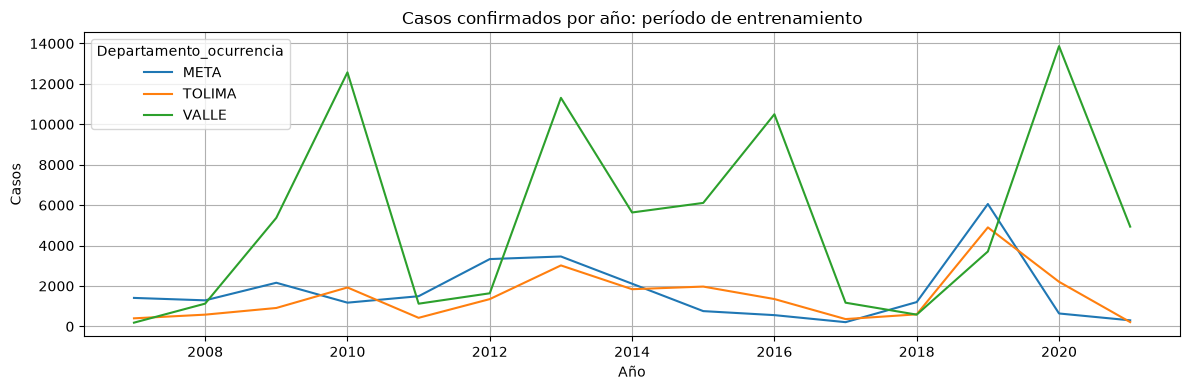

In [6]:
exploracion = casos.loc[casos.fecha.dt.year.le(CONFIG['anio_fin_train'])]
display(casos[['fecha', 'divipola', 'Departamento_ocurrencia', 'Municipio_ocurrencia']].head())
display(exploracion.groupby('Departamento_ocurrencia').agg(
    casos=('fecha', 'size'), municipios=('divipola', 'nunique'),
    primera_fecha=('fecha', 'min'), ultima_fecha=('fecha', 'max')))
display(casos_raw.isna().sum().rename('faltantes_originales').to_frame())
display(clima.loc[clima.fecha.dt.year.le(CONFIG['anio_fin_train']),
                  ['temp_mean_c', 'rain_mm_day']].isna().sum().rename('faltantes_clima').to_frame())
exploracion.groupby([exploracion.fecha.dt.year, 'Departamento_ocurrencia']).size().unstack().plot(
    title='Casos confirmados por año: período de entrenamiento', ylabel='Casos', xlabel='Año')
plt.tight_layout()
plt.show()
del exploracion

## 6. Panel semanal y definición de la etiqueta
Construimos una fila por municipio y semana epidemiológica CDC (domingo a sábado).
Sumamos casos y lluvia; promediamos temperatura. El clima semanal exige siete días válidos.

Una semana con cobertura departamental y sin casos confirmados se representa con cero;
sin cobertura conserva un valor desconocido. Excluimos semanas iniciales/finales incompletas.

In [7]:
def calendario(fechas):
    fechas = pd.to_datetime(fechas)
    unicas = fechas.dropna().drop_duplicates()
    mapa = {f: pd.Timestamp(Week.fromdate(f.date(), system='cdc').startdate()) for f in unicas}
    return fechas.map(mapa)

notificaciones['semana'] = calendario(notificaciones['fecha'])
casos['semana'] = calendario(casos['fecha'])
nombres = (notificaciones.sort_values('fecha').drop_duplicates('divipola', keep='last')
           .set_index('divipola')[['Municipio_ocurrencia', 'Departamento_ocurrencia']]
           .rename(columns={'Municipio_ocurrencia': 'municipio',
                            'Departamento_ocurrencia': 'departamento'}))
conteos = casos.groupby(['divipola', 'semana']).size().rename('casos')
cobertura = (notificaciones.assign(depto=notificaciones.divipola // 1000)
             .groupby(['depto', 'semana']).size().rename('notificaciones_depto'))

clima['semana'] = calendario(clima.fecha)
clima_semanal = clima.groupby(['divipola', 'semana']).agg(
    temperatura=('temp_mean_c', 'mean'), lluvia=('rain_mm_day', lambda s: s.sum(min_count=7)),
    dias_temp=('temp_mean_c', 'count'), dias_lluvia=('rain_mm_day', 'count'))
clima_semanal.loc[clima_semanal.dias_temp.lt(7), 'temperatura'] = np.nan
clima_semanal.loc[clima_semanal.dias_lluvia.lt(7), 'lluvia'] = np.nan

inicio = max(notificaciones.fecha.min(), clima.fecha.min(), pd.Timestamp(f"{CONFIG['anio_inicio']}-01-01"))
fin = min(notificaciones.fecha.max(), clima.fecha.max())
semanas = pd.date_range(inicio.normalize(), fin.normalize(), freq='W-SUN')
semanas = semanas[semanas + pd.Timedelta(days=6) <= fin.normalize()]
municipios_comunes = sorted(set(nombres.index) & set(clima.divipola))
if not municipios_comunes or semanas.empty:
    raise ValueError('No hay cobertura común de casos y clima en los departamentos seleccionados.')
print('Municipios sin clima:', len(set(nombres.index) - set(municipios_comunes)))
indice = pd.MultiIndex.from_product([municipios_comunes, semanas], names=['divipola', 'semana'])
panel = pd.DataFrame(index=indice).join(conteos).join(clima_semanal).reset_index()
panel['depto'] = panel.divipola // 1000
panel = panel.merge(cobertura.reset_index(), on=['depto', 'semana'], how='left', validate='many_to_one')
panel['cobertura_casos'] = panel.notificaciones_depto.notna()
panel.loc[panel.cobertura_casos, 'casos'] = panel.loc[panel.cobertura_casos, 'casos'].fillna(0)
panel = panel.join(nombres, on='divipola')
panel['anio_epi'] = panel.semana.map(lambda f: Week.fromdate(f.date()).year)
panel['semana_epi'] = panel.semana.map(lambda f: Week.fromdate(f.date()).week)
panel = panel.sort_values(['divipola', 'semana']).reset_index(drop=True)
assert not panel.duplicated(['divipola', 'semana']).any()
assert panel.groupby('divipola').semana.diff().dropna().eq(pd.Timedelta(weeks=1)).all()
print('Cobertura común completa:', semanas.min().date(), 'a', (semanas.max() + pd.Timedelta(days=6)).date())
display(panel.groupby('departamento').agg(municipios=('divipola', 'nunique'),
    semanas_sin_cobertura=('cobertura_casos', lambda s: (~s).sum()),
    temperatura_faltante=('temperatura', lambda s: s.isna().sum())))
display(panel.head())
del clima, casos_raw, notificaciones, casos

Municipios sin clima: 0


Cobertura común completa: 2007-01-07 a 2025-12-27


,municipios,semanas_sin_cobertura,temperatura_faltante
departamento,,,
META,29,0,145
TOLIMA,47,0,235
VALLE,42,0,210


,divipola,semana,casos,temperatura,lluvia,dias_temp,dias_lluvia,depto,notificaciones_depto,cobertura_casos,municipio,departamento,anio_epi,semana_epi
0,50001,2007-01-07,8.0,25.402569,2.478411,7.0,7.0,50,13,True,VILLAVICENCIO,META,2007,2
1,50001,2007-01-14,16.0,25.734522,10.369330,7.0,7.0,50,27,True,VILLAVICENCIO,META,2007,3
2,50001,2007-01-21,11.0,25.917483,2.575110,7.0,7.0,50,28,True,VILLAVICENCIO,META,2007,4
3,50001,2007-01-28,7.0,26.557080,0.000000,7.0,7.0,50,23,True,VILLAVICENCIO,META,2007,5
4,50001,2007-02-04,7.0,26.218399,0.000000,7.0,7.0,50,22,True,VILLAVICENCIO,META,2007,6


### Elegibilidad municipal y etiqueta t+4
La elegibilidad exige diez años con casos y 200 casos acumulados, usando solamente datos
hasta 2021. El **umbral de la etiqueta** es el P75 histórico por municipio y semana,
con referencia 2007–2019 excluyendo 2010, 2013, 2016 y 2019.
Para la semana 53 se conserva el respaldo con semanas 52 y 1.

Definimos brote como `casos > P75`; la etiqueta de una secuencia en t es el estado en t+4.
Esta definición es retrospectiva. El canal que entra a la red se calculará por separado para
no utilizar años futuros en las características. P75 igual a cero conserva su significado actual:
cualquier caso positivo supera el umbral.

In [8]:
entrenamiento = panel.loc[panel.anio_epi.le(CONFIG['anio_fin_train'])]
anuales = entrenamiento.groupby(['divipola', 'anio_epi']).casos.sum(min_count=1)
elegibilidad = anuales.groupby('divipola').agg(
    anios_con_casos=lambda s: s.gt(0).sum(), casos_acumulados=lambda s: s.sum(min_count=1))
elegibles = elegibilidad.index[
    elegibilidad.anios_con_casos.ge(CONFIG['min_anios_con_casos'])
    & elegibilidad.casos_acumulados.ge(CONFIG['min_casos_train'])]
if len(elegibles) == 0:
    raise ValueError('Ningún municipio cumple la elegibilidad con entrenamiento.')
panel = panel.loc[panel.divipola.isin(elegibles)].copy().reset_index(drop=True)
referencia = panel.loc[panel.anio_epi.between(CONFIG['referencia_inicio'], CONFIG['referencia_fin'])
                       & ~panel.anio_epi.isin(CONFIG['excluir_referencia'])]
canal = referencia.groupby(['divipola', 'semana_epi']).casos.quantile(.75).unstack()
canal = canal.reindex(index=sorted(elegibles), columns=range(1, 54))
fallback_53 = referencia.loc[referencia.semana_epi.isin([52, 1])].groupby('divipola').casos.quantile(.75)
canal[53] = canal[53].fillna(fallback_53)
umbrales = canal.rename_axis(columns='semana_epi').stack().rename('p75').reset_index()
panel = panel.merge(umbrales, on=['divipola', 'semana_epi'], how='left', validate='many_to_one')
panel = panel.sort_values(['divipola', 'semana']).reset_index(drop=True)
panel['brote'] = np.where(panel.casos.notna() & panel.p75.notna(), (panel.casos > panel.p75).astype(float), np.nan)
grupo = panel.groupby('divipola', sort=False)
panel['objetivo'] = grupo.brote.shift(-CONFIG['horizonte'])
panel['semana_objetivo'] = grupo.semana.shift(-CONFIG['horizonte'])
panel['anio_objetivo'] = panel.semana_objetivo.map(
    lambda f: Week.fromdate(f.date()).year if pd.notna(f) else np.nan)
validas = panel.semana_objetivo.notna()
assert (panel.loc[validas, 'semana_objetivo'] - panel.loc[validas, 'semana']).eq(
    pd.Timedelta(weeks=CONFIG['horizonte'])).all()
print('Municipios elegibles:', len(elegibles))
display(elegibilidad.loc[elegibles].join(nombres).sort_values('casos_acumulados', ascending=False))
display(panel.groupby('anio_objetivo').objetivo.agg(['count', 'mean']).rename(columns={'mean':'proporcion_brote'}))

Municipios elegibles: 51


,anios_con_casos,casos_acumulados,municipio,departamento
divipola,,,,
76001,15,53732.0,CALI,VALLE
50001,15,15349.0,VILLAVICENCIO,META
73001,15,9420.0,IBAGUE,TOLIMA
76520,15,5174.0,PALMIRA,VALLE
50006,15,3175.0,ACACIAS,META
76111,15,2551.0,BUGA,VALLE
76834,15,2498.0,TULUA,VALLE
76147,15,2076.0,CARTAGO,VALLE
73268,15,1885.0,ESPINAL,TOLIMA


,count,proporcion_brote
anio_objetivo,,
2007.0,2397,0.067167
2008.0,2703,0.115427
2009.0,2652,0.213047
2010.0,2652,0.237934
2011.0,2652,0.070513
2012.0,2652,0.170060
2013.0,2652,0.514329
2014.0,2703,0.325194
2015.0,2652,0.240950


## 7. Ingeniería de características
Las once variables son casos, temperatura, lluvia, seno/coseno de la semana, dos indicadores
de clima faltante, P75 histórico y sus medias de 3/6/9 semanas.
Los indicadores permiten identificar cuándo un valor climático fue imputado.

El **P75 de entrada** usa solo años anteriores al año de cada observación y exige al menos
tres años distintos de referencia. Desde 2020 la referencia permanece congelada hasta 2019
(con las exclusiones indicadas). La alternativa para semana 53 también respeta estas reglas.

In [9]:
panel['semana_sin'] = np.sin(2 * np.pi * (panel.semana_epi - 1) / 52.1775)
panel['semana_cos'] = np.cos(2 * np.pi * (panel.semana_epi - 1) / 52.1775)
for columna in ['temperatura', 'lluvia']:
    panel[f'{columna}_faltante'] = panel[columna].isna().astype(float)


def construir_referencia_historica(datos):
    """Calcula cada P75 con años pasados; no recibe etiquetas futuras."""
    referencia = datos.loc[
        datos.anio_epi.between(CONFIG['referencia_inicio'], CONFIG['referencia_fin'])
        & ~datos.anio_epi.isin(CONFIG['excluir_referencia']) & datos.casos.notna()]
    tablas = []
    for corte in sorted(datos.corte_referencia.unique()):
        pasado = referencia.loc[referencia.anio_epi.le(corte)]
        if pasado.empty:
            continue
        tabla = pasado.groupby(['divipola', 'semana_epi']).agg(
            p75_historico=('casos', lambda s: s.quantile(.75)),
            n_anios_referencia=('anio_epi', 'nunique'),
            ultimo_anio_referencia=('anio_epi', 'max'))
        tabla = tabla.loc[tabla.n_anios_referencia.ge(CONFIG['min_anios_referencia'])].reset_index()
        tabla['fallback_53'] = False
        # Contamos años distintos, no filas de las dos semanas vecinas.
        respaldo = pasado.loc[pasado.semana_epi.isin([52, 1])].groupby('divipola').agg(
            p75_historico=('casos', lambda s: s.quantile(.75)),
            n_anios_referencia=('anio_epi', 'nunique'),
            ultimo_anio_referencia=('anio_epi', 'max'))
        existentes = tabla.loc[tabla.semana_epi.eq(53), 'divipola']
        respaldo = respaldo.loc[
            respaldo.n_anios_referencia.ge(CONFIG['min_anios_referencia'])
            & ~respaldo.index.isin(existentes)].reset_index()
        respaldo['semana_epi'], respaldo['fallback_53'] = 53, True
        tabla = pd.concat([tabla, respaldo], ignore_index=True)
        tabla['corte_referencia'] = int(corte)
        tablas.append(tabla)
    if not tablas:
        raise ValueError('No hay años suficientes para construir el canal histórico.')
    columnas = ['divipola', 'semana_epi', 'corte_referencia', 'p75_historico',
                'n_anios_referencia', 'ultimo_anio_referencia', 'fallback_53']
    return pd.concat(tablas, ignore_index=True)[columnas].sort_values(
        ['corte_referencia', 'divipola', 'semana_epi']).reset_index(drop=True)


panel['corte_referencia'] = np.minimum(panel.anio_epi - 1, CONFIG['referencia_fin']).astype(int)
referencia_historica = construir_referencia_historica(panel)
panel = panel.merge(referencia_historica, on=['divipola', 'semana_epi', 'corte_referencia'],
                    how='left', validate='many_to_one').sort_values(['divipola', 'semana']).reset_index(drop=True)
conocidas = panel.p75_historico.notna()
assert (panel.loc[conocidas, 'ultimo_anio_referencia'] < panel.loc[conocidas, 'anio_epi']).all()
assert panel.loc[conocidas, 'n_anios_referencia'].ge(CONFIG['min_anios_referencia']).all()

### Medias móviles del canal
Cada media incluye la semana actual y las anteriores; nunca está centrada.
Exigimos la ventana completa y mantenemos los valores desconocidos como faltantes.
Doce pasos con una media de nueve semanas pueden resumir hasta veinte semanas de canal.

In [10]:
for ventana_media in CONFIG['ventanas_medias']:
    panel[f'p75_media_{ventana_media}'] = panel.groupby('divipola').p75_historico.transform(
        lambda s: s.rolling(ventana_media, min_periods=ventana_media, center=False).mean())
display(panel.loc[panel.p75_media_9.notna(), ['municipio', 'semana', *FEATURES]].head(8))
print('Último año usado como referencia:', referencia_historica.ultimo_anio_referencia.max())
print('Filas sin P75 histórico suficiente:', panel.p75_historico.isna().sum())

,municipio,semana,casos,temperatura,lluvia,semana_sin,semana_cos,temperatura_faltante,lluvia_faltante,p75_historico,p75_media_3,p75_media_6,p75_media_9
165,VILLAVICENCIO,2010-03-07,23.0,26.356288,97.237305,0.883731,0.467996,0.0,0.0,18.0,21.000000,18.333333,18.333333
166,VILLAVICENCIO,2010-03-14,39.0,25.792945,77.361453,0.933551,0.358445,0.0,0.0,12.5,19.666667,18.250000,17.500000
167,VILLAVICENCIO,2010-03-21,16.0,26.125756,39.881411,0.969850,0.243703,0.0,0.0,24.5,18.333333,20.000000,18.111111
168,VILLAVICENCIO,2010-03-28,22.0,25.417865,95.871395,0.992102,0.125432,0.0,0.0,19.5,18.833333,19.916667,18.500000
169,VILLAVICENCIO,2010-04-04,22.0,23.626472,186.251858,0.999986,0.005344,0.0,0.0,28.0,24.000000,21.833333,20.166667
170,VILLAVICENCIO,2010-04-11,34.0,23.414331,165.461115,0.993386,-0.114822,0.0,0.0,26.0,24.500000,21.416667,21.500000
171,VILLAVICENCIO,2010-04-18,30.0,24.716441,130.310138,0.972399,-0.233325,0.0,0.0,31.0,28.333333,23.583333,22.722222
172,VILLAVICENCIO,2010-04-25,26.0,24.363798,110.217640,0.937328,-0.348448,0.0,0.0,24.0,27.000000,25.500000,23.555556


Último año usado como referencia: 2018
Filas sin P75 histórico suficiente: 8058


## 8. Secuencias, split y preprocesamiento
Para reproducir el experimento conservamos su requisito de **26 semanas válidas de historia**.
Este requisito selecciona las muestras; la entrada de la red usa **solo las últimas doce**.
No buscamos ni entrenamos un modelo de 26 semanas en este libro.

Cada ventana pertenece a un único municipio y termina en t. La etiqueta corresponde a t+4.

In [11]:
filas_validas = (panel.cobertura_casos.to_numpy() & panel.casos.notna().to_numpy()
                 & np.isfinite(panel[FEATURES[-4:]].to_numpy(dtype=float)).all(axis=1))
historias = []
for _, filas in panel.groupby('divipola', sort=False):
    posiciones = filas.index.to_numpy()
    if len(posiciones) < CONFIG['historia_minima']:
        continue
    ventanas = np.lib.stride_tricks.sliding_window_view(posiciones, CONFIG['historia_minima'])
    finales = ventanas[:, -1]
    validas = (filas_validas[ventanas].all(axis=1)
               & panel.objetivo.notna().to_numpy()[finales]
               & panel.brote.notna().to_numpy()[finales])
    historias.append(ventanas[validas].copy())
if not historias or not any(len(h) for h in historias):
    raise ValueError('No hay secuencias con cobertura, etiqueta y canal suficientes.')
indices = np.concatenate(historias)[:, -CONFIG['ventana']:].copy()
meta = panel.loc[indices[:, -1], ['divipola', 'municipio', 'departamento', 'semana',
    'semana_objetivo', 'anio_objetivo', 'objetivo', 'brote']].reset_index(drop=True)
y = meta.objetivo.to_numpy(dtype='float32')
assert not meta.duplicated(['divipola', 'semana_objetivo']).any()
assert np.all(panel.divipola.to_numpy()[indices] == meta.divipola.to_numpy()[:, None])
assert np.all(np.diff(panel.semana.to_numpy()[indices], axis=1) == np.timedelta64(7, 'D'))
assert np.all(panel.semana.to_numpy()[indices] <= meta.semana.to_numpy()[:, None])
assert (meta.semana_objetivo - meta.semana).eq(pd.Timedelta(weeks=CONFIG['horizonte'])).all()
print('Secuencias disponibles:', len(meta), '| Entrada:', (CONFIG['ventana'], len(FEATURES)))

Secuencias disponibles: 38862 | Entrada: (12, 11)


### Partición cronológica
Train termina en 2021; validation abarca 2022–2023 y test, 2024–2025.
Excluimos las primeras cuatro semanas objetivo **al inicio de cada bloque posterior**, no de cada año.
Además verificamos que su origen sea posterior a la última etiqueta usada en el bloque anterior.
Esta separación evita utilizar etiquetas que todavía no estarían disponibles al predecir.

In [12]:
mascaras = {'train': meta.anio_objetivo.le(CONFIG['anio_fin_train']).to_numpy()}
for nombre, anios, anterior in [('validation', CONFIG['anios_validation'], 'train'),
                                ('test', CONFIG['anios_test'], 'validation')]:
    candidata = meta.anio_objetivo.isin(anios).to_numpy()
    primeras = sorted(meta.loc[candidata, 'semana_objetivo'].unique())[:CONFIG['purga_semanas']]
    limite = meta.loc[mascaras[anterior], 'semana_objetivo'].max()
    mascaras[nombre] = (candidata & ~meta.semana_objetivo.isin(primeras).to_numpy()
                       & meta.semana.gt(limite).to_numpy())
for nombre, mascara in mascaras.items():
    if mascara.sum() == 0 or np.unique(y[mascara]).size < 2:
        raise ValueError(f'{nombre}: se requieren muestras de ambas clases.')
assert np.all(sum(mascaras.values()) <= 1)
for anterior, siguiente in [('train', 'validation'), ('validation', 'test')]:
    assert set(meta.loc[mascaras[anterior], 'semana_objetivo']).isdisjoint(
        meta.loc[mascaras[siguiente], 'semana_objetivo'])
    assert meta.loc[mascaras[siguiente], 'semana'].min() > meta.loc[
        mascaras[anterior], 'semana_objetivo'].max()
resumen_particiones = pd.DataFrame([{
    'particion': nombre, 'secuencias': int(m.sum()), 'municipios': meta.loc[m, 'divipola'].nunique(),
    'desde_objetivo': meta.loc[m, 'semana_objetivo'].min(),
    'hasta_objetivo': meta.loc[m, 'semana_objetivo'].max(), 'proporcion_brote': float(y[m].mean()),
} for nombre, m in mascaras.items()])
display(resumen_particiones)
print('Secuencias excluidas por separación temporal:', int((sum(mascaras.values()) == 0).sum()))

,particion,secuencias,municipios,desde_objetivo,hasta_objetivo,proporcion_brote
0,train,28254,51,2010-09-26,2021-12-26,0.247363
1,validation,5100,51,2022-01-30,2023-12-24,0.418431
2,test,5100,51,2024-01-28,2025-12-21,0.582549


Secuencias excluidas por separación temporal: 408


### Compatibilidad de los artefactos
Antes de reutilizar un modelo comprobamos datos, muestras, variables, configuración y versiones.
La huella de los archivos detecta cambios accidentales; no implica entrenar con test.
Si cambió algo, el mensaje indicará que debe activarse `REENTRENAR=True`.

In [13]:
def sha256_archivo(ruta):
    h = hashlib.sha256()
    with ruta.open('rb') as archivo:
        for bloque in iter(lambda: archivo.read(8 * 1024 * 1024), b''):
            h.update(bloque)
    return h.hexdigest()


def hash_muestras(mascara):
    claves = meta.loc[mascara, ['divipola', 'semana', 'semana_objetivo', 'objetivo']]
    return hashlib.sha256(pd.util.hash_pandas_object(claves, index=False).to_numpy().tobytes()).hexdigest()


def verificar_archivos(carpeta, requeridos):
    archivo = carpeta / 'manifest.json'
    if not archivo.exists():
        raise ValueError(f'Paquete incompleto: {carpeta}. Usa REENTRENAR=True.')
    manifiesto = json.loads(archivo.read_text())
    if not set(requeridos).issubset(manifiesto['archivos']):
        raise ValueError('El manifiesto está incompleto. Usa REENTRENAR=True.')
    for nombre in requeridos:
        ruta = carpeta / nombre
        if not ruta.is_file() or sha256_archivo(ruta) != manifiesto['archivos'][nombre]:
            raise ValueError(f'Artefacto alterado o ausente: {ruta}. Usa REENTRENAR=True.')
    return manifiesto


ARCHIVOS = ['modelo.keras', 'preprocesamiento.joblib', 'referencia_historica.parquet',
            'umbrales.csv', 'configuracion.json', 'historia.json', 'decision.json',
            'predicciones_validation.csv']
VERSIONES = {'tensorflow': tf.__version__, 'sklearn': sklearn.__version__,
             'numpy': np.__version__, 'pandas': pd.__version__, 'keras': tf.keras.__version__}
identidad = {'config': CONFIG, 'parametros': PARAMETROS, 'features': FEATURES,
    'fuentes': {'casos': sha256_archivo(CASOS), 'clima': sha256_archivo(CLIMA)},
    'versiones': VERSIONES, 'elegibles': sorted(int(v) for v in elegibles),
    'muestras': {nombre: hash_muestras(m) for nombre, m in mascaras.items()}}
firma = hashlib.sha256(json.dumps(identidad, sort_keys=True).encode()).hexdigest()
ACCION, carpeta_carga = 'entrenar', None
if not REENTRENAR:
    if (SALIDA / 'manifest.json').exists():
        manifiesto = verificar_archivos(SALIDA, ARCHIVOS)
        guardada = json.loads((SALIDA / 'configuracion.json').read_text())
        if guardada['identidad'] != identidad or manifiesto['firma'] != firma:
            raise ValueError('Los artefactos finales son incompatibles. Usa REENTRENAR=True.')
        ACCION, carpeta_carga = 'cargar', SALIDA
    elif any((SALIDA / nombre).exists() for nombre in ARCHIVOS):
        raise ValueError('Hay artefactos finales incompletos. Usa REENTRENAR=True.')
    elif ORIGEN.exists():
        ACCION, carpeta_carga = 'importar', ORIGEN
print('Acción del pipeline:', ACCION)

Acción del pipeline: importar


### Reutilización inicial del finalista
Esta comprobación solo se usa la primera vez, si todavía no existe el paquete final.
Los pesos se reutilizan junto con su preprocesamiento y umbral. Si el experimento original
no está disponible, el pipeline puede entrenar desde los CSV con la configuración fija.

In [14]:
def verificar_finalista(carpeta):
    requeridos = ['modelo.keras', 'preprocesamiento.joblib', 'referencia_historica.parquet',
                  'configuracion.json', 'historia.json', 'decision.json', 'predicciones_calibracion.csv']
    verificar_archivos(carpeta, requeridos)
    ajuste = json.loads((carpeta / 'configuracion.json').read_text())
    experimento = json.loads((carpeta.parent.parent / 'configuracion.json').read_text())
    base = experimento['base']
    claves_datos = ['departamentos', 'anio_inicio', 'anio_fin_train', 'anios_validation', 'anios_test',
                   'referencia_inicio', 'referencia_fin', 'excluir_referencia',
                   'min_anios_con_casos', 'min_casos_train', 'horizonte']
    compatibles = [
        ajuste['parametros'] == PARAMETROS, ajuste['features'] == FEATURES,
        ajuste['ventana'] == CONFIG['ventana'], base['fuentes'] == identidad['fuentes'],
        ajuste['datos']['elegibles'] == identidad['elegibles'],
        ajuste['datos']['hash_train'] == identidad['muestras']['train'],
        ajuste['datos']['hash_calibracion'] == identidad['muestras']['validation'],
        ajuste['datos']['definicion'] == {'train_hasta': CONFIG['anio_fin_train'],
            'calibracion': CONFIG['anios_validation'], 'evaluacion': CONFIG['anios_test']},
        all(base['config'][k] == CONFIG[k] for k in claves_datos),
        all(ajuste[k] == CONFIG[k] for k in ['semilla', 'epochs', 'paciencia']),
        max(experimento['config']['ventanas']) == CONFIG['historia_minima'],
        experimento['config']['purga_semanas'] == CONFIG['purga_semanas'],
        all(experimento['canal'][k] == CONFIG[k] for k in ['min_anios_referencia', 'ventanas_medias']),
        all(VERSIONES[k] == v for k, v in base['versiones'].items()),
        experimento['versiones_extra']['keras'] == VERSIONES['keras'],
    ]
    if not all(compatibles):
        raise ValueError('El finalista no coincide con este pipeline. Usa REENTRENAR=True.')
    pd.testing.assert_frame_equal(referencia_historica,
                                  pd.read_parquet(carpeta / 'referencia_historica.parquet'))


if ACCION == 'importar':
    verificar_finalista(ORIGEN)
    print('Finalista compatible:', ORIGEN.name)

Finalista compatible: w12_7f26a5e6e4


### Imputación y escalado
Imputamos clima faltante con la mediana y estandarizamos las once entradas.
Ajustamos estos pasos sobre las **filas únicas de entrenamiento**: así las semanas repetidas
entre ventanas no reciben más peso por aparecer varias veces. Al cargar se reutiliza el ajuste guardado.

In [15]:
filas_train = np.unique(indices[mascaras['train']].ravel())
if ACCION == 'cargar':
    preprocesamiento = joblib.load(carpeta_carga / 'preprocesamiento.joblib')
else:
    preprocesamiento = Pipeline([
        ('imputador', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('escalador', StandardScaler()),
    ])
    preprocesamiento.fit(panel.loc[filas_train, FEATURES])
    if ACCION == 'importar':
        previo = joblib.load(ORIGEN / 'preprocesamiento.joblib')
        np.testing.assert_allclose(preprocesamiento['imputador'].statistics_,
                                   previo['imputador'].statistics_, rtol=0, atol=1e-12)
        for atributo in ['mean_', 'var_', 'scale_']:
            np.testing.assert_allclose(getattr(preprocesamiento['escalador'], atributo),
                                       getattr(previo['escalador'], atributo), rtol=0, atol=1e-12)
        preprocesamiento = previo
assert panel.loc[filas_train, 'semana'].max() <= meta.loc[mascaras['train'], 'semana'].max()
particiones = {}
for nombre, mascara in mascaras.items():
    posiciones = indices[mascara]
    x = preprocesamiento.transform(panel.loc[posiciones.ravel(), FEATURES]).astype('float32')
    x = x.reshape(len(posiciones), CONFIG['ventana'], len(FEATURES))
    assert np.isfinite(x).all()
    particiones[nombre] = (x, y[mascara])
    print(nombre, '| X:', x.shape, '| y:', y[mascara].shape)

train | X: (28254, 12, 11) | y: (28254,)
validation | X: (5100, 12, 11) | y: (5100,)
test | X: (5100, 12, 11) | y: (5100,)


## 9. Hiperparámetros seleccionados
La búsqueda previa seleccionó esta configuración por F2 medio en tres cortes temporales:
**0,704**. La selección ocurrió antes de consultar el test final.
En esta versión los valores están fijados: no repetimos la búsqueda.

El umbral del modelo existente es **0,12654227018356323** y se carga desde su archivo de decisión.
No es un hiperparámetro de la red: se obtuvo con validation. Si entrenamos de nuevo, se volverá
a elegir sobre validation después de restaurar los mejores pesos.

In [16]:
display(pd.DataFrame({
    'parámetro': ['Ventana de entrada', 'Características', 'LSTM', 'Dropout', 'Dense ReLU',
                 'Learning rate', 'Batch size', 'Máximo de épocas', 'Paciencia', 'Semilla', 'Peso positivo'],
    'valor': [CONFIG['ventana'], len(FEATURES), PARAMETROS['unidades_1'], PARAMETROS['dropout'],
              PARAMETROS['dense'], PARAMETROS['learning_rate'], PARAMETROS['batch_size'],
              CONFIG['epochs'], CONFIG['paciencia'], CONFIG['semilla'], 1],
}))

,parámetro,valor
0,Ventana de entrada,12.000000
1,Características,11.000000
2,LSTM,32.000000
3,Dropout,0.000000
4,Dense ReLU,16.000000
5,Learning rate,0.001282
6,Batch size,256.000000
7,Máximo de épocas,30.000000
8,Paciencia,5.000000
9,Semilla,42.000000


## 10. Definición del modelo
La LSTM resume la secuencia; la capa Dense combina esa representación y la salida sigmoide
produce un score entre 0 y 1. El score no se considera una probabilidad calibrada.
Dropout cero conserva la arquitectura seleccionada sin descartar unidades durante el ajuste.

In [17]:
def construir_modelo():
    modelo = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(CONFIG['ventana'], len(FEATURES))),
        tf.keras.layers.LSTM(PARAMETROS['unidades_1']),
        tf.keras.layers.Dropout(PARAMETROS['dropout']),
        tf.keras.layers.Dense(PARAMETROS['dense'], activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid'),
    ])
    modelo.compile(optimizer=tf.keras.optimizers.Adam(PARAMETROS['learning_rate']),
                   loss='binary_crossentropy', metrics=[tf.keras.metrics.AUC(curve='PR', name='pr_auc')])
    return modelo

modelo = construir_modelo()
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         5,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,177 (24.13 KB)

 Trainable params: 6,177 (24.13 KB)

 Non-trainable params: 0 (0.00 B)

## 11. Entrenamiento o carga
Usamos una sola red y entropía cruzada binaria sin pesos adicionales.
Al finalizar cada época calculamos el máximo F2 en validation. La parada temprana observa
ese valor y restaura los mejores pesos.

La búsqueda del umbral evalúa todos los scores distintos, incluyendo juntos los empates.
Desempata por precisión y después por mayor umbral. **Test no participa** en este procedimiento.

In [18]:
def predecir_scores(modelo, x):
    """Inferencia por lotes, sin crear pools de hilos adicionales."""
    batch = PARAMETROS['batch_size']
    return np.concatenate([modelo(x[i:i + batch], training=False).numpy().ravel()
                           for i in range(0, len(x), batch)])

In [19]:
def evaluar(y_real, scores, umbral):
    real = np.asarray(y_real, dtype=int)
    scores = np.asarray(scores, dtype=float)
    if real.ndim != 1 or scores.shape != real.shape or real.size == 0:
        raise ValueError('Etiquetas y scores deben ser vectores no vacíos del mismo tamaño.')
    if not np.isin(real, [0, 1]).all() or not np.isfinite(scores).all():
        raise ValueError('Se requieren etiquetas binarias y scores finitos.')
    if not np.isfinite(umbral) or not 0 <= umbral <= 1:
        raise ValueError('El umbral debe estar entre 0 y 1.')
    pred = scores >= umbral
    tn, fp, fn, tp = (int(v) for v in confusion_matrix(real, pred, labels=[0, 1]).ravel())
    positivos, negativos = tp + fn, tn + fp
    dos_clases = positivos > 0 and negativos > 0
    return {'n': int(real.size), 'umbral': float(umbral), 'prevalencia': float(real.mean()),
        'tp': tp, 'tn': tn, 'fn': fn, 'fp': fp,
        'precision': tp / (tp + fp) if tp + fp else 0.0,
        'recall': tp / positivos if positivos else 0.0,
        'f1': 2 * tp / (2 * tp + fn + fp) if 2 * tp + fn + fp else 0.0,
        'f2': 5 * tp / (5 * tp + 4 * fn + fp) if 5 * tp + 4 * fn + fp else 0.0,
        'fnr': fn / positivos if positivos else np.nan,
        'fpr': fp / negativos if negativos else np.nan,
        'proporcion_alertas': float(pred.mean()),
        'pr_auc_ap': float(average_precision_score(real, scores)) if dos_clases else np.nan,
        'roc_auc': float(roc_auc_score(real, scores)) if dos_clases else np.nan}

def optimizar_umbral(y_val, scores_val):
    """Busca F2 exacto por grupos de scores; no recibe datos de test."""
    y_val = np.asarray(y_val)
    scores_val = np.asarray(scores_val, dtype=float)
    if (y_val.ndim != 1 or scores_val.shape != y_val.shape or np.unique(y_val).size != 2
        or not np.isin(y_val, [0, 1]).all() or not np.isfinite(scores_val).all()
        or ((scores_val < 0) | (scores_val > 1)).any()):
        raise ValueError('La selección de umbral requiere ambas clases y scores válidos entre 0 y 1.')
    orden = np.argsort(-scores_val, kind='stable')
    s, y_orden = scores_val[orden], y_val[orden].astype(int)
    # Un score empatado entra completo: la decisión operativa siempre es score >= umbral.
    finales = np.flatnonzero(np.r_[s[1:] != s[:-1], True])
    tp = np.cumsum(y_orden)[finales]
    fp = finales + 1 - tp
    fn = y_orden.sum() - tp
    tabla = pd.DataFrame({'umbral': s[finales],
        'f2': 5 * tp / (5 * tp + 4 * fn + fp), 'precision': tp / (tp + fp)})
    mejor = tabla.sort_values(['f2', 'precision', 'umbral'], ascending=False).iloc[0]
    return evaluar(y_val, scores_val, float(mejor.umbral))

In [20]:
class ValidacionF2(tf.keras.callbacks.Callback):
    """Publica F2 antes de que EarlyStopping decida si continuar."""
    def __init__(self, x_val, y_val):
        super().__init__()
        self.x_val, self.y_val = x_val, y_val

    def on_epoch_end(self, epoch, logs=None):
        punto = optimizar_umbral(self.y_val, predecir_scores(self.model, self.x_val))
        if logs is not None:
            logs['val_f2_optimo'] = punto['f2']
            logs['val_umbral_f2'] = punto['umbral']
            logs['val_recall_f2'] = punto['recall']


def dataset_tf(x, etiquetas):
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 1
    opciones.threading.max_intra_op_parallelism = 1
    return tf.data.Dataset.from_tensor_slices((x, etiquetas)).batch(
        PARAMETROS['batch_size']).with_options(opciones)


x_val, y_val = particiones['validation']
if ACCION in ['cargar', 'importar']:
    modelo = tf.keras.models.load_model(carpeta_carga / 'modelo.keras', compile=False)
    historia = json.loads((carpeta_carga / 'historia.json').read_text())
    decision = json.loads((carpeta_carga / 'decision.json').read_text())
    print('Modelo cargado: se omite el entrenamiento.')
else:
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(CONFIG['semilla'])
    modelo = construir_modelo()
    parada = tf.keras.callbacks.EarlyStopping(monitor='val_f2_optimo', mode='max',
        patience=CONFIG['paciencia'], restore_best_weights=True)
    print('Entrenando una única configuración fija.', flush=True)
    ajuste = modelo.fit(dataset_tf(*particiones['train']),
        validation_data=dataset_tf(x_val, y_val), epochs=CONFIG['epochs'],
        callbacks=[ValidacionF2(x_val, y_val), parada], shuffle=False, verbose=2)
    historia = {k: [float(v) for v in valores] for k, valores in ajuste.history.items()}
    decision = optimizar_umbral(y_val, predecir_scores(modelo, x_val))
    np.testing.assert_allclose(decision['f2'], max(historia['val_f2_optimo']), atol=1e-7)

umbral = float(decision['umbral'])
scores_val = predecir_scores(modelo, x_val)
if ACCION in ['cargar', 'importar']:
    archivo_val = 'predicciones_calibracion.csv' if ACCION == 'importar' else 'predicciones_validation.csv'
    previas = pd.read_csv(carpeta_carga / archivo_val, converters={'score': float, 'umbral': float})
    np.testing.assert_array_equal(y_val.astype(int), previas.real)
    np.testing.assert_allclose(scores_val, previas.score, rtol=1e-6, atol=1e-7)
    np.testing.assert_array_equal(scores_val >= umbral, previas.prediccion)
metricas_validation = evaluar(y_val, scores_val, umbral)
display(pd.DataFrame([metricas_validation]))
print('Umbral que se utilizará para inferencia:', umbral)

Modelo cargado: se omite el entrenamiento.


,n,umbral,prevalencia,tp,tn,fn,fp,precision,recall,f1,f2,fnr,fpr,proporcion_alertas,pr_auc_ap,roc_auc
0,5100,0.126542,0.418431,1937,1628,197,1338,0.59145,0.907685,0.716214,0.819998,0.092315,0.451113,0.642157,0.847003,0.862453


Umbral que se utilizará para inferencia: 0.12654227018356323


## 12. Guardado y reutilización
El paquete final contiene modelo `.keras`, preprocesamiento, referencias históricas,
umbrales de la etiqueta, configuración, historia y decisión de inferencia.
El umbral y la red pertenecen a una misma decisión; no se sustituye el umbral por 0,5 al cargar.

La primera ejecución copia el modelo compatible a su carpeta final. Las siguientes lo cargan.
Comprobamos la recarga con toda validation antes de evaluar test.

In [21]:
SALIDA.mkdir(parents=True, exist_ok=True)
if ACCION != 'cargar':
    # El manifiesto se escribe al final: un guardado interrumpido no se reutiliza.
    (SALIDA / 'manifest.json').unlink(missing_ok=True)
    if ACCION == 'importar':
        shutil.copy2(ORIGEN / 'modelo.keras', SALIDA / 'modelo.keras')
        shutil.copy2(ORIGEN / 'preprocesamiento.joblib', SALIDA / 'preprocesamiento.joblib')
    else:
        modelo.save(SALIDA / 'modelo.keras')
        joblib.dump(preprocesamiento, SALIDA / 'preprocesamiento.joblib')
    referencia_historica.to_parquet(SALIDA / 'referencia_historica.parquet', index=False)
    umbrales.to_csv(SALIDA / 'umbrales.csv', index=False)
    procedencia = {'accion': ACCION, 'origen': str(ORIGEN.relative_to(RAIZ)) if ACCION == 'importar' else None}
    (SALIDA / 'configuracion.json').write_text(json.dumps(
        {'identidad': identidad, 'procedencia': procedencia}, indent=2, ensure_ascii=False))
    (SALIDA / 'historia.json').write_text(json.dumps(historia, indent=2))
    (SALIDA / 'decision.json').write_text(json.dumps(decision, indent=2))
    pd.DataFrame({'real': y_val.astype(int), 'score': scores_val.astype(float),
                  'umbral': umbral, 'prediccion': (scores_val >= umbral).astype(int)}).to_csv(
                      SALIDA / 'predicciones_validation.csv', index=False)
    (SALIDA / 'manifest.json').write_text(json.dumps(
        {'firma': firma, 'archivos': {n: sha256_archivo(SALIDA / n) for n in ARCHIVOS}}, indent=2))


def cargar_artefactos(carpeta):
    verificar_archivos(carpeta, ARCHIVOS)
    return {'modelo': tf.keras.models.load_model(carpeta / 'modelo.keras', compile=False),
            'preprocesamiento': joblib.load(carpeta / 'preprocesamiento.joblib'),
            'decision': json.loads((carpeta / 'decision.json').read_text()),
            'configuracion': json.loads((carpeta / 'configuracion.json').read_text())}


recarga = cargar_artefactos(SALIDA)
ids_val = indices[mascaras['validation']]
x_recarga = recarga['preprocesamiento'].transform(panel.loc[ids_val.ravel(), FEATURES]).astype('float32')
x_recarga = x_recarga.reshape(len(ids_val), CONFIG['ventana'], len(FEATURES))
scores_recarga = predecir_scores(recarga['modelo'], x_recarga)
np.testing.assert_allclose(scores_recarga, scores_val, rtol=1e-6, atol=1e-7)
np.testing.assert_array_equal(scores_recarga >= recarga['decision']['umbral'], scores_val >= umbral)
# Usamos la red y el umbral que realmente quedaron guardados.
modelo, preprocesamiento = recarga['modelo'], recarga['preprocesamiento']
umbral = float(recarga['decision']['umbral'])
resumen_particiones.to_csv(SALIDA / 'particiones.csv', index=False)
print('Recarga verificada. Modelo y umbral disponibles en:', SALIDA)

Recarga verificada. Modelo y umbral disponibles en: /home/sergioba/code/university/microproyecto-tema3/models/lstm/final


## 13. Resultados de inferencia
Aplicamos el umbral de validation a test sin reajustarlo. Cada fila identifica el municipio,
la última semana observada, la semana objetivo, el estado real y la decisión del modelo.
El gráfico permite revisar cuándo los scores anticipan brotes y cuándo generan falsas alarmas.

,municipio,semana,semana_objetivo,objetivo,score,umbral,prediccion
0,VILLAVICENCIO,2023-12-31,2024-01-28,1.0,0.533341,0.126542,1
1,VILLAVICENCIO,2024-01-07,2024-02-04,1.0,0.533977,0.126542,1
2,VILLAVICENCIO,2024-01-14,2024-02-11,0.0,0.472006,0.126542,1
3,VILLAVICENCIO,2024-01-21,2024-02-18,1.0,0.439112,0.126542,1
4,VILLAVICENCIO,2024-01-28,2024-02-25,0.0,0.549647,0.126542,1
5,VILLAVICENCIO,2024-02-04,2024-03-03,0.0,0.664120,0.126542,1
6,VILLAVICENCIO,2024-02-11,2024-03-10,0.0,0.497811,0.126542,1
7,VILLAVICENCIO,2024-02-18,2024-03-17,1.0,0.423534,0.126542,1
8,VILLAVICENCIO,2024-02-25,2024-03-24,0.0,0.413603,0.126542,1
9,VILLAVICENCIO,2024-03-03,2024-03-31,1.0,0.220270,0.126542,1


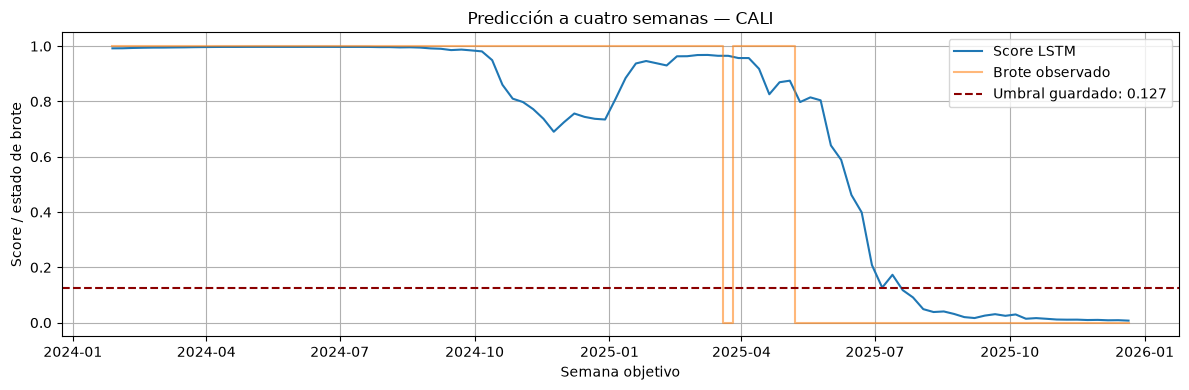

In [22]:
x_test, y_test = particiones['test']
scores_test = predecir_scores(modelo, x_test)
inferencias = meta.loc[mascaras['test']].reset_index(drop=True).copy()
inferencias['score'] = scores_test.astype(float)
inferencias['umbral'] = umbral
inferencias['prediccion'] = (scores_test >= umbral).astype(int)
inferencias.to_csv(SALIDA / 'inferencias_test.csv', index=False)
display(inferencias[['municipio', 'semana', 'semana_objetivo', 'objetivo', 'score', 'umbral', 'prediccion']].head(15))

# Seleccionamos el municipio con más casos en train, sin buscar el mejor ejemplo en test.
codigo_ejemplo = elegibilidad.loc[elegibles, 'casos_acumulados'].idxmax()
ejemplo = inferencias.loc[inferencias.divipola.eq(codigo_ejemplo)].sort_values('semana_objetivo')
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ejemplo.semana_objetivo, ejemplo.score, label='Score LSTM')
ax.step(ejemplo.semana_objetivo, ejemplo.objetivo, where='mid', alpha=.55, label='Brote observado')
ax.axhline(umbral, color='darkred', linestyle='--', label=f'Umbral guardado: {umbral:.3f}')
ax.set(title=f'Predicción a cuatro semanas — {ejemplo.municipio.iloc[0]}',
       xlabel='Semana objetivo', ylabel='Score / estado de brote', ylim=(-.05, 1.05))
ax.legend()
plt.tight_layout()
fig.savefig(SALIDA / 'ejemplo_inferencia.png', dpi=150)
plt.show()

## 14. Rendimiento
Evaluamos con la distribución original de test, sin ponderar métricas.
Reportamos FN y FP junto con F2, recall, precisión, F1, AP, ROC-AUC y porcentaje de alertas.
Las métricas municipales sin ambas clases muestran AUC desconocida en lugar de inventar un valor.

Comparamos con dos reglas sin entrenamiento: persistencia (mantener el estado observado en t)
y anunciar brote siempre. La segunda ayuda a detectar cuándo un recall elevado se obtiene
emitiendo alertas indiscriminadamente. **Este test ya fue consultado y sigue siendo exploratorio.**

,modelo,n,umbral,prevalencia,tp,tn,fn,fp,precision,recall,f1,f2,fnr,fpr,proporcion_alertas,pr_auc_ap,roc_auc
0,LSTM final,5100,0.126542,0.582549,2896,561,75,1568,0.648746,0.974756,0.779018,0.885735,0.025244,0.736496,0.875294,0.906025,0.860040
1,Persistencia,5100,0.500000,0.582549,2407,1453,564,676,0.780733,0.810165,0.795177,0.804102,0.189835,0.317520,0.604510,0.743111,0.746322
2,Siempre brote,5100,0.500000,0.582549,2971,0,0,2129,0.582549,1.000000,0.736216,0.874647,0.000000,1.000000,1.000000,0.582549,0.500000


,municipio,n,fn,fp,recall,precision,f2,pr_auc_ap
0,VILLAVICENCIO,100,0,21,1.000000,0.790000,0.949519,0.904327
1,ACACIAS,100,0,25,1.000000,0.750000,0.937500,0.907846
2,CASTILLA LA NUEVA,100,2,24,0.966102,0.703704,0.899054,0.840295
3,CUMARAL,100,4,41,0.914894,0.511905,0.790441,0.744201
4,EL CASTILLO,100,4,32,0.906977,0.549296,0.802469,0.691781
5,GRANADA,100,0,29,1.000000,0.710000,0.924479,0.845502
6,GUAMAL,100,1,45,0.979167,0.510870,0.827465,0.653118
7,LA MACARENA,100,2,46,0.942857,0.417722,0.753425,0.471885
8,PUERTO GAITAN,100,5,14,0.938272,0.844444,0.917874,0.945581
9,PUERTO LOPEZ,100,2,26,0.967742,0.697674,0.898204,0.894160


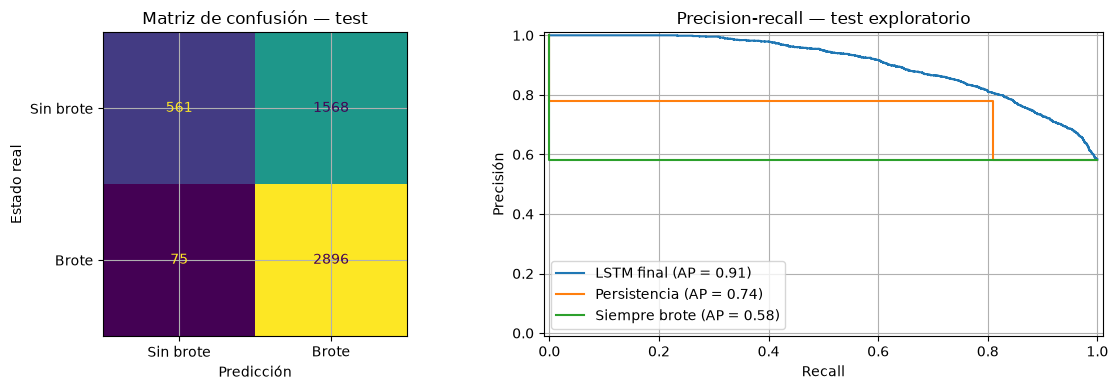

In [23]:
resultados = []
for nombre, scores, corte in [('LSTM final', scores_test, umbral),
                              ('Persistencia', inferencias.brote.to_numpy(), .5),
                              ('Siempre brote', np.ones(len(y_test)), .5)]:
    resultados.append({'modelo': nombre, **evaluar(y_test, scores, corte)})
metricas_test = pd.DataFrame(resultados)
metricas_municipales = pd.DataFrame([{
    'divipola': codigo, 'municipio': filas.municipio.iloc[0],
    'departamento': filas.departamento.iloc[0],
    **evaluar(filas.objetivo.to_numpy(), filas.score.to_numpy(), umbral),
} for codigo, filas in inferencias.groupby('divipola')])
metricas_test.to_csv(SALIDA / 'metricas_test.csv', index=False)
metricas_municipales.to_csv(SALIDA / 'metricas_por_municipio.csv', index=False)
pd.DataFrame([metricas_validation]).to_csv(SALIDA / 'metricas_validation.csv', index=False)
display(metricas_test)
with pd.option_context('display.max_rows', 60):
    display(metricas_municipales[['municipio', 'n', 'fn', 'fp', 'recall', 'precision', 'f2', 'pr_auc_ap']])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(y_test, inferencias.prediccion,
    labels=[0, 1], display_labels=['Sin brote', 'Brote'], colorbar=False, ax=axes[0])
axes[0].set(title='Matriz de confusión — test', xlabel='Predicción', ylabel='Estado real')
for nombre, scores in [('LSTM final', scores_test), ('Persistencia', inferencias.brote.to_numpy()),
                       ('Siempre brote', np.ones(len(y_test)))]:
    PrecisionRecallDisplay.from_predictions(y_test, scores, name=nombre, ax=axes[1])
axes[1].set_aspect('auto')
axes[1].set(title='Precision-recall — test exploratorio', xlabel='Recall', ylabel='Precisión')
plt.tight_layout()
fig.savefig(SALIDA / 'rendimiento_test.png', dpi=150)
plt.show()

### Curvas de aprendizaje
La pérdida describe el ajuste de los scores; F2 de validation determina la época elegida.
La historia se carga con el modelo, por lo que estas gráficas siguen disponibles sin reentrenar.

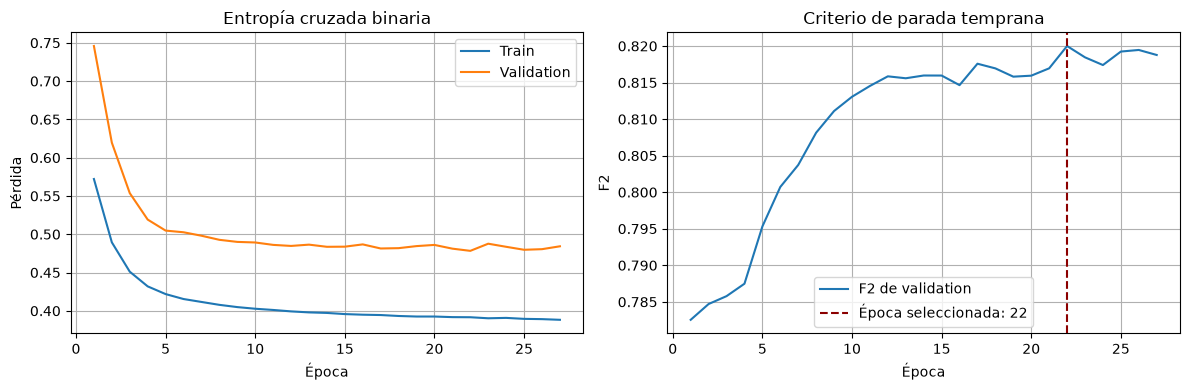

In [24]:
epocas = np.arange(1, len(historia['loss']) + 1)
mejor_epoca = int(np.argmax(historia['val_f2_optimo'])) + 1
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epocas, historia['loss'], label='Train')
axes[0].plot(epocas, historia['val_loss'], label='Validation')
axes[0].set(title='Entropía cruzada binaria', xlabel='Época', ylabel='Pérdida')
axes[0].legend()
axes[1].plot(epocas, historia['val_f2_optimo'], label='F2 de validation')
axes[1].axvline(mejor_epoca, linestyle='--', color='darkred', label=f'Época seleccionada: {mejor_epoca}')
axes[1].set(title='Criterio de parada temprana', xlabel='Época', ylabel='F2')
axes[1].legend()
plt.tight_layout()
fig.savefig(SALIDA / 'curvas_aprendizaje.png', dpi=150)
plt.show()

## 15. Resumen y conclusiones
Este resumen se genera con las métricas calculadas en la ejecución actual.

In [25]:
r = metricas_test.loc[metricas_test.modelo.eq('LSTM final')].iloc[0]
referencia_siempre = metricas_test.loc[metricas_test.modelo.eq('Siempre brote')].iloc[0]
display(Markdown(f"""
**Modelo final:** doce semanas de entrada, once características, LSTM de 32 unidades y Dense de 16.
Se seleccionó en el ejercicio previo por validación temporal; en este libro usamos su configuración fija.

- **Test exploratorio:** {int(r['n']):,} muestras de {inferencias.divipola.nunique()} municipios.
- **F2:** {r.f2:.3f}; **recall:** {r.recall:.1%}; **precisión:** {r.precision:.1%}; **AP:** {r.pr_auc_ap:.3f}.
- **Errores:** {int(r.fn):,} falsos negativos y {int(r.fp):,} falsos positivos.
- **Alertas:** {r.proporcion_alertas:.1%} de las muestras, con umbral {umbral:.6f}.
- **Referencia siempre brote:** F2 {referencia_siempre.f2:.3f}; debe considerarse al interpretar la mejora.

F2 favorece la sensibilidad, pero debemos leerla junto con las falsas alarmas.
La etiqueta retrospectiva, los umbrales P75 iguales a cero, la cobertura aproximada y la variación
entre años limitan las conclusiones. Una semilla y un test ya consultado no prueban generalización futura.
Los scores aún no tienen calibración probabilística.

**Reutilización:** el paquete final incluye la red, su preprocesamiento y el umbral.
Con `REENTRENAR=False` una nueva ejecución carga esos artefactos sin entrenar.
"""))
print('Pipeline completo. Acción ejecutada:', ACCION)


**Modelo final:** doce semanas de entrada, once características, LSTM de 32 unidades y Dense de 16.
Se seleccionó en el ejercicio previo por validación temporal; en este libro usamos su configuración fija.

- **Test exploratorio:** 5,100 muestras de 51 municipios.
- **F2:** 0.886; **recall:** 97.5%; **precisión:** 64.9%; **AP:** 0.906.
- **Errores:** 75 falsos negativos y 1,568 falsos positivos.
- **Alertas:** 87.5% de las muestras, con umbral 0.126542.
- **Referencia siempre brote:** F2 0.875; debe considerarse al interpretar la mejora.

F2 favorece la sensibilidad, pero debemos leerla junto con las falsas alarmas.
La etiqueta retrospectiva, los umbrales P75 iguales a cero, la cobertura aproximada y la variación
entre años limitan las conclusiones. Una semilla y un test ya consultado no prueban generalización futura.
Los scores aún no tienen calibración probabilística.

**Reutilización:** el paquete final incluye la red, su preprocesamiento y el umbral.
Con `REENTRENAR=False` una nueva ejecución carga esos artefactos sin entrenar.


Pipeline completo. Acción ejecutada: importar
